<a href="https://colab.research.google.com/github/BaruJahnavi/ECOM-fro-pvp/blob/main/Road_Accident_Severity_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Step 2: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)

All libraries imported successfully!
Pandas version: 2.2.3


In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
# Step 4: Load the dataset

import pandas as pd

train_df = pd.read_csv('/content/train.csv')
test_df = pd.read_csv('/content/test.csv')

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nFirst 5 rows of the training dataset:")
display(train_df.head())

Training dataset shape: (8210, 33)
Testing dataset shape: (4106, 32)

First 5 rows of the training dataset:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Num,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,1,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,2,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,3,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,5,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [ ]:
# Step 5: Explore the dataset

print("Column names:")
print(train_df.columns.tolist())

print("\nDataset information:")
train_df.info()

print("\nMissing values in each column:")
print(train_df.isnull().sum())

print("\nTarget column candidates:")
print([col for col in train_df.columns if 'severity' in col.lower()])

Column names:
['Num', 'Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Number_of_vehicles_involved', 'Number_of_casualties', 'Vehicle_movement', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement', 'Cause_of_accident', 'Accident_severity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8210 entries, 0 to 8209
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Num                          8210 non-null   int

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Accident severity counts:
Accident_severity
Slight Injury     7082
Serious Injury    1046
Fatal injury        82
Name: count, dtype: int64

Accident severity percentages:
Accident_severity
Slight Injury     86.26
Serious Injury    12.74
Fatal injury       1.00
Name: proportion, dtype: float64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


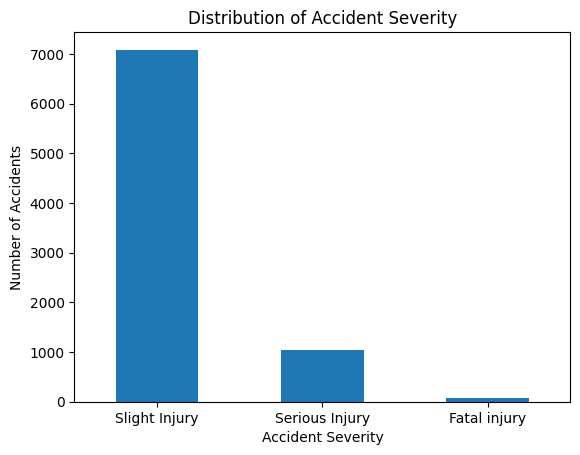

In [ ]:
# Step 6: Analyze accident severity distribution

target_column = 'Accident_severity'

if target_column in train_df.columns:
    print("Accident severity counts:")
    print(train_df[target_column].value_counts())

    print("\nAccident severity percentages:")
    print(
        (train_df[target_column].value_counts(normalize=True) * 100)
        .round(2)
    )

    train_df[target_column].value_counts().plot(
        kind='bar',
        title='Distribution of Accident Severity',
        xlabel='Accident Severity',
        ylabel='Number of Accidents',
        rot=0
    )

    plt.show()
else:
    print("Target column not found. Please check the column names from Step 5.")

In [ ]:
# Step 7: Separate features and target

target_column = 'Accident_severity'

if target_column in train_df.columns:
    X = train_df.drop(columns=[target_column])
    y = train_df[target_column]

    print("Features shape:", X.shape)
    print("Target shape:", y.shape)

    print("\nTarget classes:")
    print(y.value_counts())

    print("\nFeature columns:")
    print(X.columns.tolist())
else:
    print("Target column not found.")
    print("Available columns:", train_df.columns.tolist())

Features shape: (8210, 32)
Target shape: (8210,)

Target classes:
Accident_severity
Slight Injury     7082
Serious Injury    1046
Fatal injury        82
Name: count, dtype: int64

Feature columns:
['Num', 'Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Number_of_vehicles_involved', 'Number_of_casualties', 'Vehicle_movement', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement', 'Cause_of_accident']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Step 8: Identify column data types

print("Numerical columns:")
print(X.select_dtypes(include=['number']).columns.tolist())

print("\nCategorical columns:")
print(X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist())

print("\nTotal missing values in features:", X.isnull().sum().sum())

print("\nTotal missing values in target:", y.isnull().sum())

Numerical columns:
['Num', 'Number_of_vehicles_involved', 'Number_of_casualties']

Categorical columns:
['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Vehicle_movement', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement', 'Cause_of_accident']

Total missing values in features: 12870

Total missing values in target: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Step 9: Prepare data using preprocessing

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(include=['number']).columns.tolist()
categorical_columns = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Process numerical columns
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Process categorical columns
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_columns),
    ('cat', categorical_transformer, categorical_columns)
])

# Split data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Numerical columns:", len(numerical_columns))
print("Categorical columns:", len(categorical_columns))
print("Data preparation setup completed successfully!")

Training samples: 6568
Validation samples: 1642
Numerical columns: 3
Categorical columns: 29
Data preparation setup completed successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Step 10: Train the Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create the model pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Model Evaluation Results
------------------------
Accuracy: 0.9080 (90.80%)
Balanced Accuracy: 0.6827

Classification Report:
                precision    recall  f1-score   support

  Fatal injury       0.67      0.47      0.55        17
Serious Injury       0.68      0.62      0.65       209
 Slight Injury       0.94      0.96      0.95      1416

      accuracy                           0.91      1642
     macro avg       0.76      0.68      0.72      1642
  weighted avg       0.90      0.91      0.91      1642



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


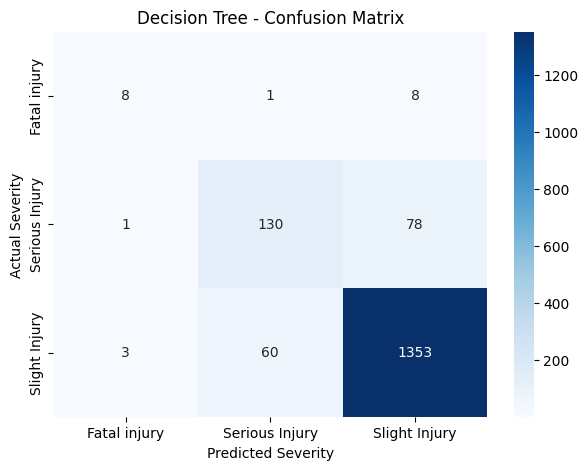

In [ ]:
# Step 11: Evaluate the Decision Tree model

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Predict accident severity for validation data
y_pred = model.predict(X_val)

# Calculate evaluation metrics
accuracy = accuracy_score(y_val, y_pred)
balanced_accuracy = balanced_accuracy_score(y_val, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_pred, zero_division=0))

# Display confusion matrix
cm = confusion_matrix(y_val, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.show()

In [ ]:
# Step 12: Train an improved Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

improved_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the improved model
improved_model.fit(X_train, y_train)

print("Improved Decision Tree trained successfully!")
print("Maximum tree depth: 10")
print("Minimum samples to split: 20")
print("Minimum samples per leaf: 10")
print("Class weighting: balanced")

Improved Decision Tree trained successfully!
Maximum tree depth: 10
Minimum samples to split: 20
Minimum samples per leaf: 10
Class weighting: balanced


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Step 13: Compare both Decision Tree models

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
import pandas as pd

# Predictions from both models
y_pred_original = model.predict(X_val)
y_pred_improved = improved_model.predict(X_val)

# Compare evaluation metrics
comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Balanced Accuracy',
        'Macro F1 Score'
    ],
    'Original Decision Tree': [
        accuracy_score(y_val, y_pred_original),
        balanced_accuracy_score(y_val, y_pred_original),
        f1_score(y_val, y_pred_original, average='macro', zero_division=0)
    ],
    'Improved Decision Tree': [
        accuracy_score(y_val, y_pred_improved),
        balanced_accuracy_score(y_val, y_pred_improved),
        f1_score(y_val, y_pred_improved, average='macro', zero_division=0)
    ]
})

print("Model Comparison Results:")
display(comparison.round(4))

Model Comparison Results:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Metric,Original Decision Tree,Improved Decision Tree
0,Accuracy,0.9080,0.6754
1,Balanced Accuracy,0.6827,0.5853
2,Macro F1 Score,0.7165,0.4221


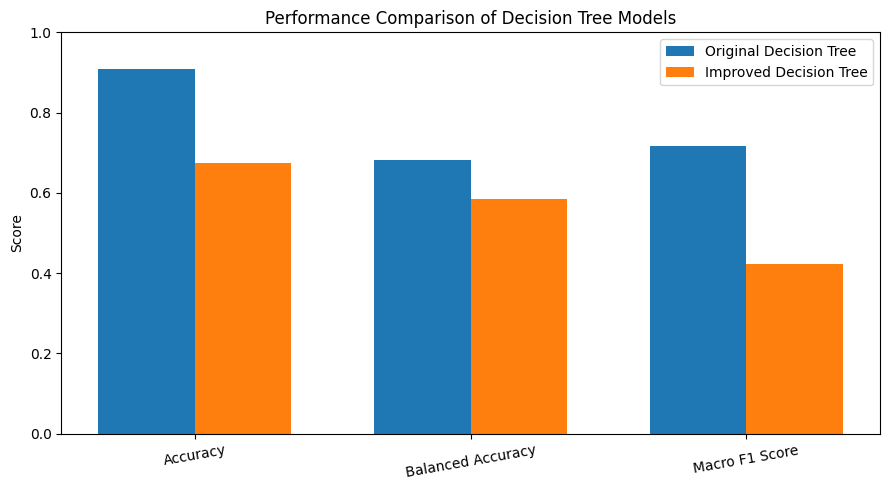

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Step 14: Visualize model comparison

import matplotlib.pyplot as plt
import numpy as np

metrics = comparison['Metric']
original_scores = comparison['Original Decision Tree']
improved_scores = comparison['Improved Decision Tree']

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    original_scores,
    width,
    label='Original Decision Tree'
)

plt.bar(
    x + width / 2,
    improved_scores,
    width,
    label='Improved Decision Tree'
)

plt.xticks(x, metrics, rotation=10)
plt.ylabel('Score')
plt.title('Performance Comparison of Decision Tree Models')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

Top 15 Important Features:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Feature,Importance
0,num__Num,0.2609
1,num__Number_of_vehicles_involved,0.1302
2,num__Number_of_casualties,0.1047
1112,cat__Weather_conditions_Normal,0.0432
1000,cat__Day_of_week_Thursday,0.0372
1106,cat__Light_conditions_Darkness - lights lit,0.0350
997,cat__Day_of_week_Monday,0.0311
1189,cat__Cause_of_accident_Moving Backward,0.0307
1003,cat__Age_band_of_driver_18-30,0.0265
998,cat__Day_of_week_Saturday,0.0244


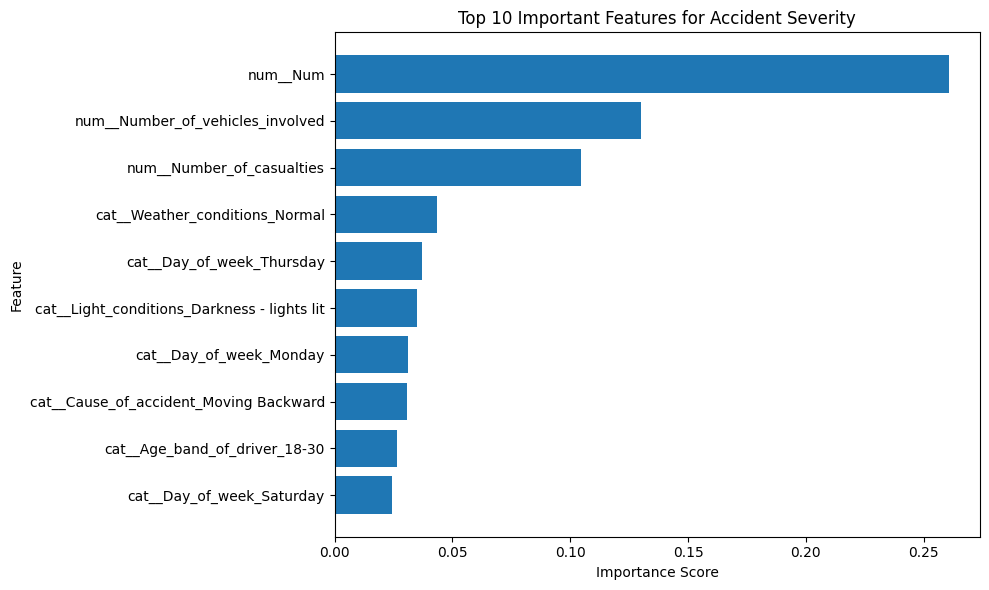

In [ ]:
# Step 15: Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Decision Tree classifier
tree_model = improved_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = improved_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Create a feature importance table
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': tree_model.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15).round(4))

# Plot the top 10 features
top_features = importance_df.head(10).sort_values(
    by='Importance'
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Important Features for Accident Severity")
plt.tight_layout()
plt.show()

Classification Report - Improved Decision Tree
                precision    recall  f1-score   support

  Fatal injury       0.10      0.59      0.17        17
Serious Injury       0.22      0.46      0.30       209
 Slight Injury       0.91      0.71      0.79      1416

      accuracy                           0.68      1642
     macro avg       0.41      0.59      0.42      1642
  weighted avg       0.81      0.68      0.73      1642



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


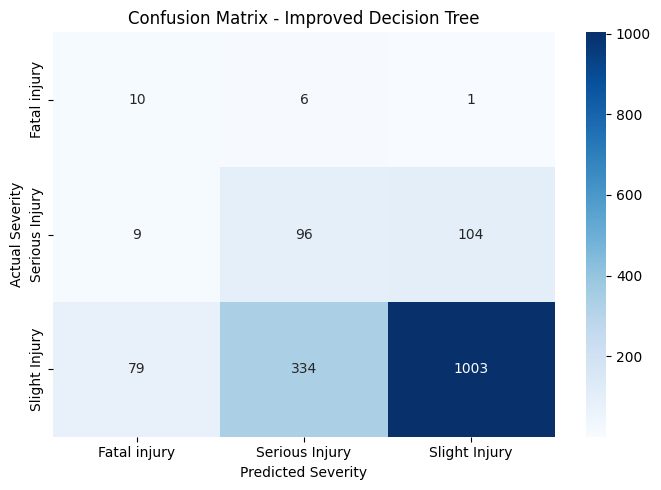

In [ ]:
# Step 16: Detailed evaluation of the improved model

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predict using the improved model
y_pred_improved = improved_model.predict(X_val)

# Classification report
print("Classification Report - Improved Decision Tree")
print(
    classification_report(
        y_val,
        y_pred_improved,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_val,
    y_pred_improved,
    labels=improved_model.classes_
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=improved_model.classes_,
    yticklabels=improved_model.classes_
)

plt.title("Confusion Matrix - Improved Decision Tree")
plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.tight_layout()
plt.show()

In [ ]:
# Step 17: Predict accident severity for test data

# Check whether the test dataset contains the target column
if target_column in test_df.columns:
    print("The test dataset contains actual severity labels.")
    print("Use a separate evaluation only if these labels are available.")
else:
    # Generate predictions using the improved model
    test_predictions = improved_model.predict(test_df)

    # Create a results table
    predictions_df = pd.DataFrame({
        'Predicted_Accident_Severity': test_predictions
    })

    print("Test predictions generated successfully!")
    print("Total predictions:", len(predictions_df))

    print("\nFirst 10 predictions:")
    display(predictions_df.head(10))

Test predictions generated successfully!
Total predictions: 4106

First 10 predictions:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Predicted_Accident_Severity
0,Fatal injury
1,Fatal injury
2,Serious Injury
3,Serious Injury
4,Serious Injury
5,Serious Injury
6,Slight Injury
7,Slight Injury
8,Slight Injury
9,Serious Injury


In [ ]:
# Step 18: Save predictions to a CSV file

if 'test_predictions' in globals():
    predictions_df = pd.DataFrame({
        'Predicted_Accident_Severity': test_predictions
    })

    predictions_df.to_csv(
        'accident_severity_predictions.csv',
        index=False
    )

    print("Predictions saved successfully!")
    print("File name: accident_severity_predictions.csv")
    display(predictions_df.head(10))
else:
    print("Please run Step 17 first to generate predictions.")

Predictions saved successfully!
File name: accident_severity_predictions.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Predicted_Accident_Severity
0,Fatal injury
1,Fatal injury
2,Serious Injury
3,Serious Injury
4,Serious Injury
5,Serious Injury
6,Slight Injury
7,Slight Injury
8,Slight Injury
9,Serious Injury


In [ ]:
# Step 19: Save the improved Decision Tree model

import joblib

joblib.dump(improved_model, 'accident_severity_model.pkl')

print("Model saved successfully!")
print("File name: accident_severity_model.pkl")


Model saved successfully!
File name: accident_severity_model.pkl


In [ ]:
from google.colab import files

files.download('accident_severity_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Step 20: Final Project Summary

print("=" * 55)
print("ROAD ACCIDENT SEVERITY PREDICTION")
print("Machine Learning Mini-Project")
print("=" * 55)

print("\nAlgorithm: Decision Tree Classifier")
print("Dataset: Road Traffic Accident Severity")
print("Preprocessing: Missing-value handling and One-Hot Encoding")
print("Data split: 80% training and 20% validation")
print("Model improvement: Depth and leaf-size control")
print("Class imbalance handling: Balanced class weights")
print("Evaluation: Accuracy, Balanced Accuracy, Macro F1-score")
print("Additional analysis: Confusion Matrix and Feature Importance")
print("Output: Accident Severity Predictions CSV")
print("Saved model: accident_severity_model.pkl")

print("\nOriginal Model Accuracy:",
      round(accuracy_score(y_val, model.predict(X_val)) * 100, 2), "%")

print("Improved Model Accuracy:",
      round(accuracy_score(y_val, improved_model.predict(X_val)) * 100, 2), "%")

print("\nProject summary generated successfully!")

ROAD ACCIDENT SEVERITY PREDICTION
Machine Learning Mini-Project

Algorithm: Decision Tree Classifier
Dataset: Road Traffic Accident Severity
Preprocessing: Missing-value handling and One-Hot Encoding
Data split: 80% training and 20% validation
Model improvement: Depth and leaf-size control
Class imbalance handling: Balanced class weights
Evaluation: Accuracy, Balanced Accuracy, Macro F1-score
Additional analysis: Confusion Matrix and Feature Importance
Output: Accident Severity Predictions CSV
Saved model: accident_severity_model.pkl

Original Model Accuracy: 90.8 %
Improved Model Accuracy: 67.54 %

Project summary generated successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Step 21: Collect final evaluation results

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
import pandas as pd

results = []

for name, fitted_model in [
    ("Original Decision Tree", model),
    ("Improved Decision Tree", improved_model)
]:
    predictions = fitted_model.predict(X_val)

    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_val, predictions) * 100, 2
        ),
        "Balanced Accuracy (%)": round(
            balanced_accuracy_score(y_val, predictions) * 100, 2
        ),
        "Macro F1 Score": round(
            f1_score(
                y_val, predictions,
                average="macro",
                zero_division=0
            ), 4
        )
    })

results_df = pd.DataFrame(results)

print("FINAL MODEL EVALUATION")
display(results_df)

print("\nDataset size:", len(train_df))
print("Number of input features:", X.shape[1])
print("Target classes:", y.nunique())

FINAL MODEL EVALUATION


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,Accuracy (%),Balanced Accuracy (%),Macro F1 Score
0,Original Decision Tree,90.80,68.27,0.7165
1,Improved Decision Tree,67.54,58.53,0.4221



Dataset size: 8210
Number of input features: 32
Target classes: 3


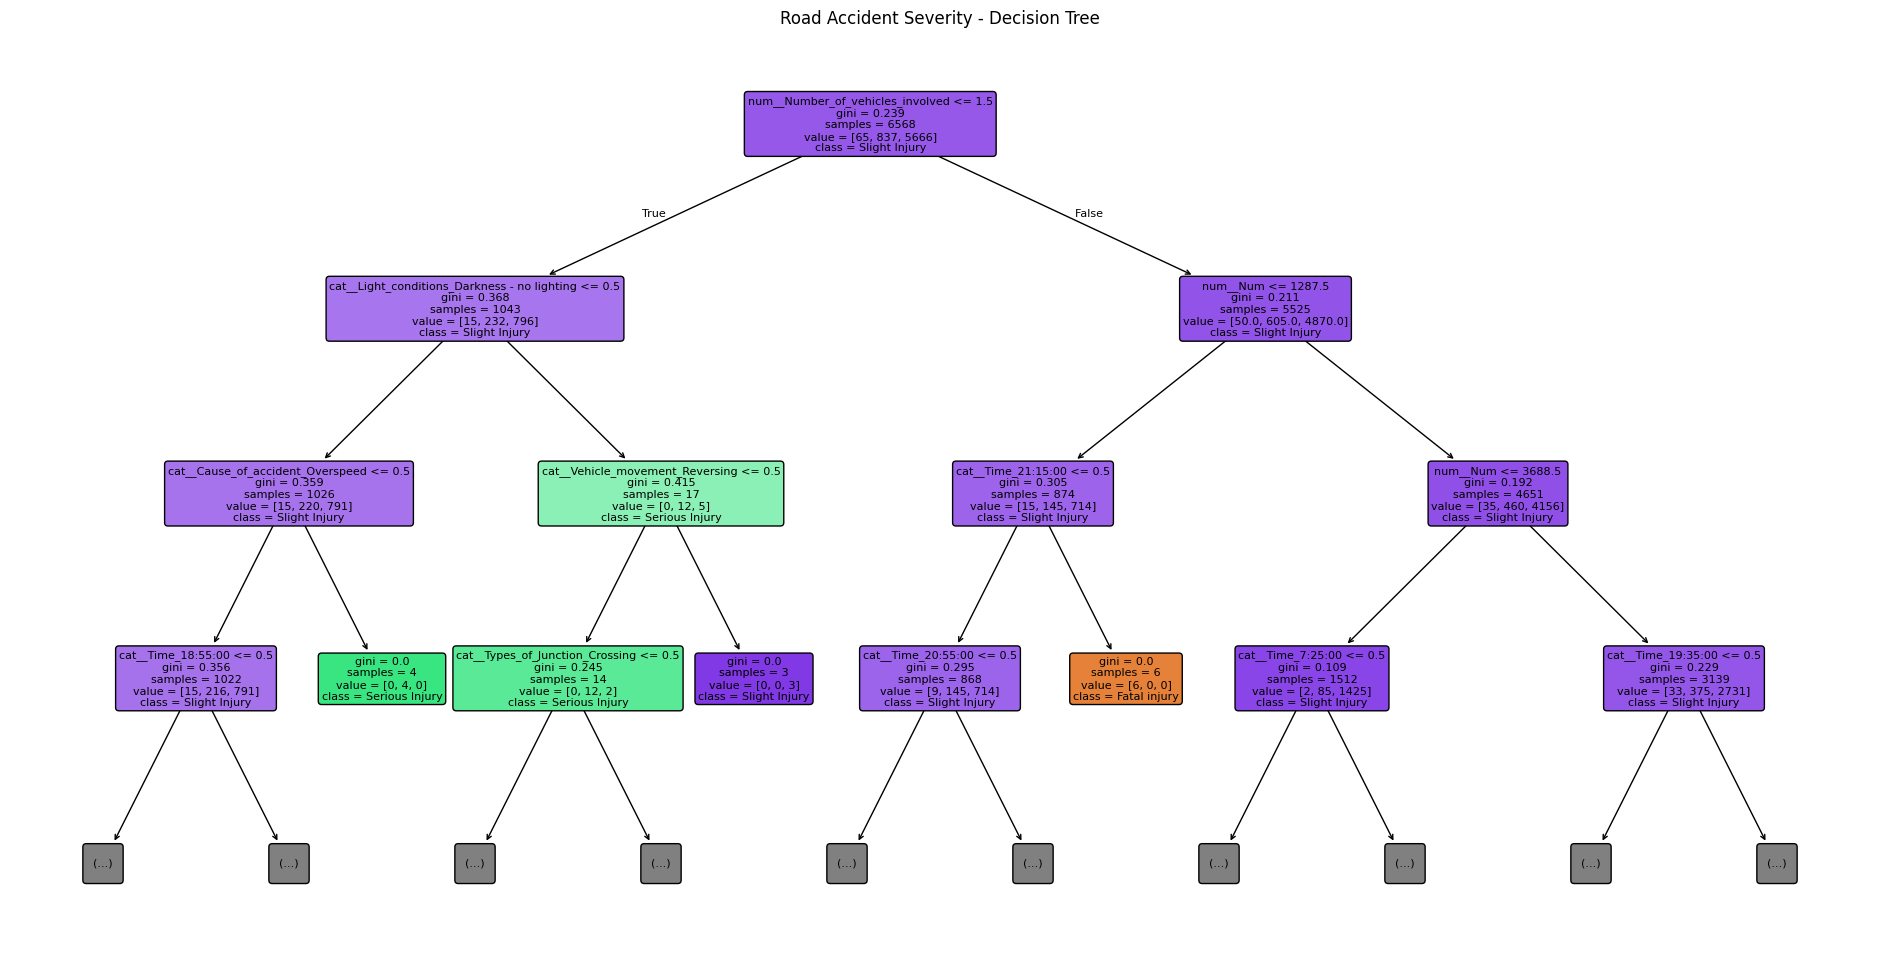

In [ ]:

# Step 22: Visualize the Decision Tree

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Get the trained Decision Tree
tree_model = model.named_steps['classifier']

# Get the feature names after preprocessing
feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Draw a readable portion of the tree
plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    max_depth=3,
    feature_names=feature_names,
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Road Accident Severity - Decision Tree")
plt.show()
